# Experiment 12
# Avani Jain
# AIML A2
# 25070126044

###### Import

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import time

##### Load Dataset
##### (as it is a very huge dataset it takes a lot of time to load so we reduced them)

In [36]:
df = pd.read_csv("/content/RT_IOT2022")

X = df.drop("Attack_type", axis=1)
y = df["Attack_type"]

print("Shape:", X.shape)

print("Classes:", y.unique())

Shape: (123117, 84)
Classes: ['MQTT_Publish' 'Thing_Speak' 'Wipro_bulb' 'ARP_poisioning'
 'DDOS_Slowloris' 'DOS_SYN_Hping' 'Metasploit_Brute_Force_SSH'
 'NMAP_FIN_SCAN' 'NMAP_OS_DETECTION' 'NMAP_TCP_scan' 'NMAP_UDP_SCAN'
 'NMAP_XMAS_TREE_SCAN']


##### Dataset Description

In [37]:
df.head()

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


In [38]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 85 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                123117 non-null  int64  
 1   id.orig_p                 123117 non-null  int64  
 2   id.resp_p                 123117 non-null  int64  
 3   proto                     123117 non-null  object 
 4   service                   123117 non-null  object 
 5   flow_duration             123117 non-null  float64
 6   fwd_pkts_tot              123117 non-null  int64  
 7   bwd_pkts_tot              123117 non-null  int64  
 8   fwd_data_pkts_tot         123117 non-null  int64  
 9   bwd_data_pkts_tot         123117 non-null  int64  
 10  fwd_pkts_per_sec          123117 non-null  float64
 11  bwd_pkts_per_sec          123117 non-null  float64
 12  flow_pkts_per_sec         123117 non-null  float64
 13  down_up_ratio             123117 non-null  f

In [39]:
df.isnull().sum().sum()


np.int64(0)

In [40]:
df["Attack_type"].value_counts()

,count
Attack_type,
DOS_SYN_Hping,94659
Thing_Speak,8108
ARP_poisioning,7750
MQTT_Publish,4146
NMAP_UDP_SCAN,2590
NMAP_XMAS_TREE_SCAN,2010
NMAP_OS_DETECTION,2000
NMAP_TCP_scan,1002
DDOS_Slowloris,534


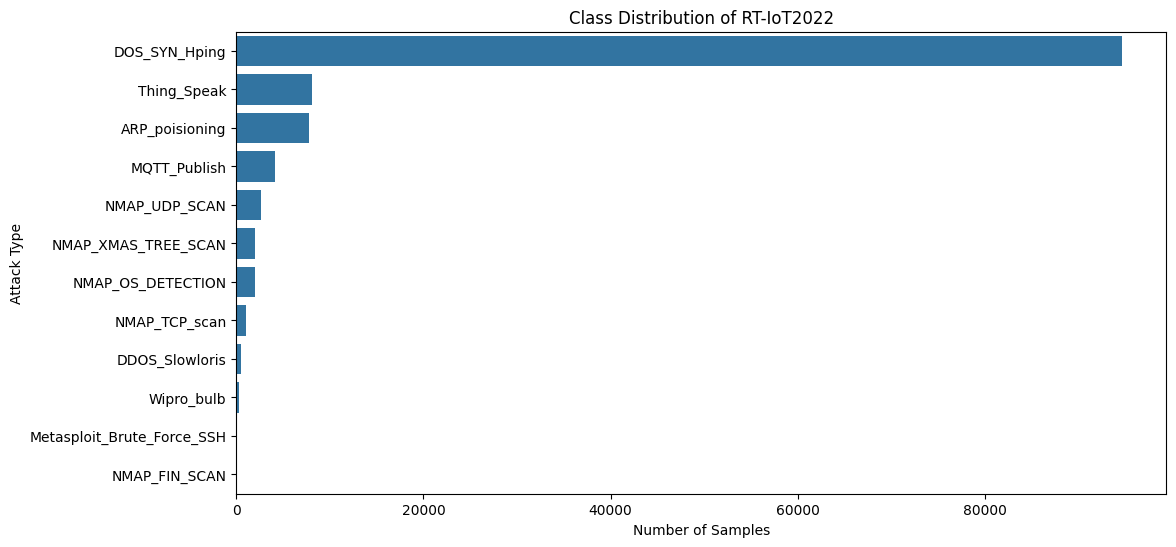

In [41]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Attack_type",
    order=df["Attack_type"].value_counts().index
)

plt.title("Class Distribution of RT-IoT2022")
plt.xlabel("Number of Samples")
plt.ylabel("Attack Type")
plt.show()

##### Separate Features and Target

In [42]:
X = df.drop("Attack_type", axis=1)
y = df["Attack_type"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)
print("Classes:", y.unique())

Feature Shape: (123117, 84)
Target Shape: (123117,)
Classes: ['MQTT_Publish' 'Thing_Speak' 'Wipro_bulb' 'ARP_poisioning'
 'DDOS_Slowloris' 'DOS_SYN_Hping' 'Metasploit_Brute_Force_SSH'
 'NMAP_FIN_SCAN' 'NMAP_OS_DETECTION' 'NMAP_TCP_scan' 'NMAP_UDP_SCAN'
 'NMAP_XMAS_TREE_SCAN']


##### Remove Irrelevant Column

In [43]:
X = X.drop("Unnamed: 0", axis=1)
print("Shape after removing ID column:", X.shape)

Shape after removing ID column: (123117, 83)


##### Check Categorical and Numerical Features

In [44]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Categorical Features:
['proto', 'service']

Number of Numerical Features: 81
Number of Categorical Features: 2


##### Encode Categorical Features

In [45]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

In [46]:
X = pd.get_dummies(X, drop_first=True)

print("Shape after encoding:", X.shape)

Shape after encoding: (123117, 92)


##### Train-Test Split

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (98493, 92)
X_test: (24624, 92)


In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


##### Naive Bayes

In [49]:
from sklearn.naive_bayes import GaussianNB

classifier = GaussianNB()

classifier.fit(X_train, y_train)

print("Model trained successfully.")
print("Classes learned:", classifier.classes_)
print("Prior probability:", np.round(classifier.class_prior_, 3))

Model trained successfully.
Classes learned: ['ARP_poisioning' 'DDOS_Slowloris' 'DOS_SYN_Hping' 'MQTT_Publish'
 'Metasploit_Brute_Force_SSH' 'NMAP_FIN_SCAN' 'NMAP_OS_DETECTION'
 'NMAP_TCP_scan' 'NMAP_UDP_SCAN' 'NMAP_XMAS_TREE_SCAN' 'Thing_Speak'
 'Wipro_bulb']
Prior probability: [0.063 0.004 0.769 0.034 0.    0.    0.016 0.008 0.021 0.016 0.066 0.002]


In [50]:
y_pred = classifier.predict(X_test)

print("Predictions completed.")
print("First 10 predictions:", y_pred[:10])

Predictions completed.
First 10 predictions: ['DOS_SYN_Hping' 'DOS_SYN_Hping' 'Metasploit_Brute_Force_SSH'
 'DOS_SYN_Hping' 'DOS_SYN_Hping' 'DOS_SYN_Hping' 'DOS_SYN_Hping'
 'NMAP_XMAS_TREE_SCAN' 'DOS_SYN_Hping' 'DOS_SYN_Hping']


In [51]:

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro Precision:", precision_score(y_test, y_pred, average="macro", zero_division=0))
print("Macro Recall:", recall_score(y_test, y_pred, average="macro", zero_division=0))
print("Macro F1:", f1_score(y_test, y_pred, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9002599090318388
Macro Precision: 0.639366458256537
Macro Recall: 0.7907120577832041
Macro F1: 0.5838717548105506

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.37      0.53      1550
            DDOS_Slowloris       0.15      0.98      0.26       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.01      1.00      0.03         7
             NMAP_FIN_SCAN       0.01      0.83      0.01         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.52      0.92      0.67       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.72      0.15      0.25      1622
                Wipro_bulb       

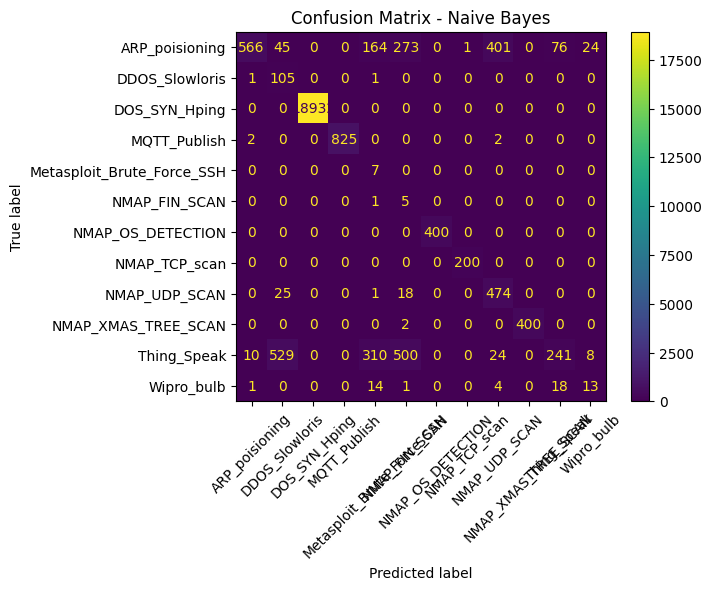

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classifier.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

##### Prepare data for SVC, Decision Tree and Random Forest

In [53]:
X_train_tree, X_test_tree, y_train_tree, y_test_tree = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

##### SVC

In [54]:
from sklearn.svm import SVC

svc = SVC(kernel="rbf")

svc.fit(X_train, y_train)

y_pred_svc = svc.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_svc))
print("Macro Precision:", precision_score(y_test, y_pred_svc, average="macro", zero_division=0))
print("Macro Recall:", recall_score(y_test, y_pred_svc, average="macro", zero_division=0))
print("Macro F1:", f1_score(y_test, y_pred_svc, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svc, zero_division=0))

Accuracy: 0.9940708252111761
Macro Precision: 0.9587146084028569
Macro Recall: 0.9181946209115056
Macro F1: 0.9318286491365074

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.95      0.99      0.97      1550
            DDOS_Slowloris       1.00      0.80      0.89       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      0.99      0.99       829
Metasploit_Brute_Force_SSH       1.00      0.86      0.92         7
             NMAP_FIN_SCAN       0.62      0.83      0.71         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.96      0.98      0.97       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.98      0.96      0.97      1622
                Wipro_bulb      

##### SVC confusion matrix

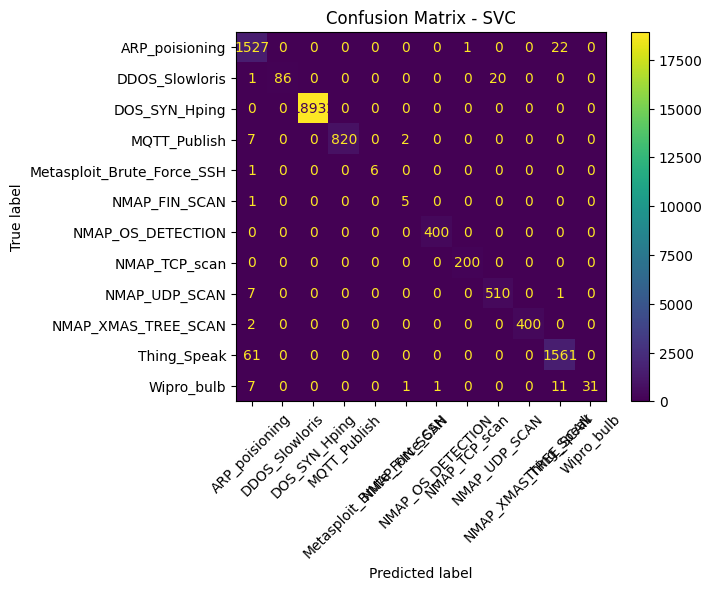

In [55]:
cm_svc = confusion_matrix(y_test, y_pred_svc)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svc,
    display_labels=svc.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Confusion Matrix - SVC")
plt.show()

##### SVC Hyperparameter Tuning

In [56]:
from sklearn.model_selection import GridSearchCV

svc_param_grid = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", "auto"],
    "kernel": ["rbf"]
}

svc_grid = GridSearchCV(
    SVC(),
    svc_param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

svc_grid.fit(X_train, y_train)

print("Best Parameters:", svc_grid.best_params_)
print("Best Macro F1:", svc_grid.best_score_)

Best Parameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Best Macro F1: 0.9463508164611351


In [57]:
best_svc = svc_grid.best_estimator_

y_pred_svc_tuned = best_svc.predict(X_test)

print("Tuned SVC Accuracy:", accuracy_score(y_test, y_pred_svc_tuned))
print("Tuned SVC Macro F1:", f1_score(y_test, y_pred_svc_tuned, average="macro"))

Tuned SVC Accuracy: 0.9952485380116959
Tuned SVC Macro F1: 0.9500876576796924


##### Decision Tree

In [58]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train_tree, y_train_tree)

y_pred_dt = dt.predict(X_test_tree)

print("Accuracy:", accuracy_score(y_test_tree, y_pred_dt))
print("Macro Precision:", precision_score(y_test_tree, y_pred_dt, average="macro", zero_division=0))
print("Macro Recall:", recall_score(y_test_tree, y_pred_dt, average="macro", zero_division=0))
print("Macro F1:", f1_score(y_test_tree, y_pred_dt, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test_tree, y_pred_dt, zero_division=0))

Accuracy: 0.9979288499025342
Macro Precision: 0.9609330202276162
Macro Recall: 0.9726470808334667
Macro F1: 0.9653088143080324

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       0.96      0.99      0.98       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       0.83      0.83      0.83         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      1.00      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb      

##### Decision Tree confusion matrix

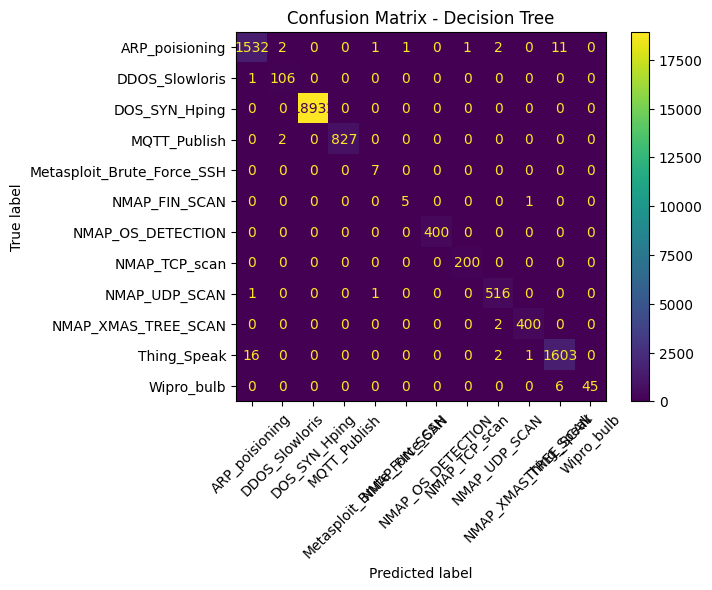

In [59]:
cm_dt = confusion_matrix(y_test_tree, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=dt.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Confusion Matrix - Decision Tree")
plt.show()

##### Decision Tree Hyperparameter Tuning

In [60]:
dt_param_grid = {
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

dt_grid.fit(X_train_tree, y_train_tree)

print("Best Parameters:", dt_grid.best_params_)
print("Best Macro F1:", dt_grid.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 2}
Best Macro F1: 0.96341238656753


In [61]:
best_dt = dt_grid.best_estimator_

y_pred_dt_tuned = best_dt.predict(X_test_tree)

print("Tuned Decision Tree Accuracy:", accuracy_score(y_test_tree, y_pred_dt_tuned))
print("Tuned Decision Tree Macro F1:", f1_score(y_test_tree, y_pred_dt_tuned, average="macro"))

Tuned Decision Tree Accuracy: 0.9979288499025342
Tuned Decision Tree Macro F1: 0.9656662333085718


##### Random Forest

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_tree, y_train_tree)

y_pred_rf = rf.predict(X_test_tree)

print("Accuracy:", accuracy_score(y_test_tree, y_pred_rf))
print("Macro Precision:", precision_score(y_test_tree, y_pred_rf, average="macro", zero_division=0))
print("Macro Recall:", recall_score(y_test_tree, y_pred_rf, average="macro", zero_division=0))
print("Macro F1:", f1_score(y_test_tree, y_pred_rf, average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test_tree, y_pred_rf, zero_division=0))

Accuracy: 0.9983349577647823
Macro Precision: 0.962869336220614
Macro Recall: 0.9779436188741683
Macro F1: 0.9692226168123531

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       1.00      0.97      0.99       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       0.83      0.83      0.83         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      0.99      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       

##### Random Forest confusion matrix

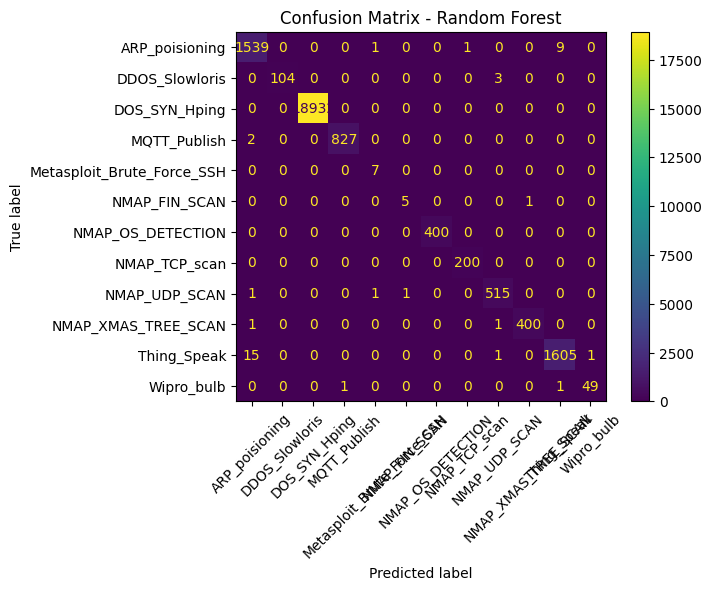

In [63]:
cm_rf = confusion_matrix(y_test_tree, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=rf.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Confusion Matrix - Random Forest")
plt.show()

##### Random Forest Hyperparameter Tuning

In [64]:
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

rf_grid.fit(X_train_tree, y_train_tree)

print("Best Parameters:", rf_grid.best_params_)
print("Best Macro F1:", rf_grid.best_score_)

Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best Macro F1: 0.9655890262023629


In [65]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test_tree)

print("Tuned Random Forest Accuracy:", accuracy_score(y_test_tree, y_pred_rf_tuned))
print("Tuned Random Forest Macro F1:", f1_score(y_test_tree, y_pred_rf_tuned, average="macro"))

Tuned Random Forest Accuracy: 0.9984567901234568
Tuned Random Forest Macro F1: 0.9759665806653688


##### Final Confusion Matrices

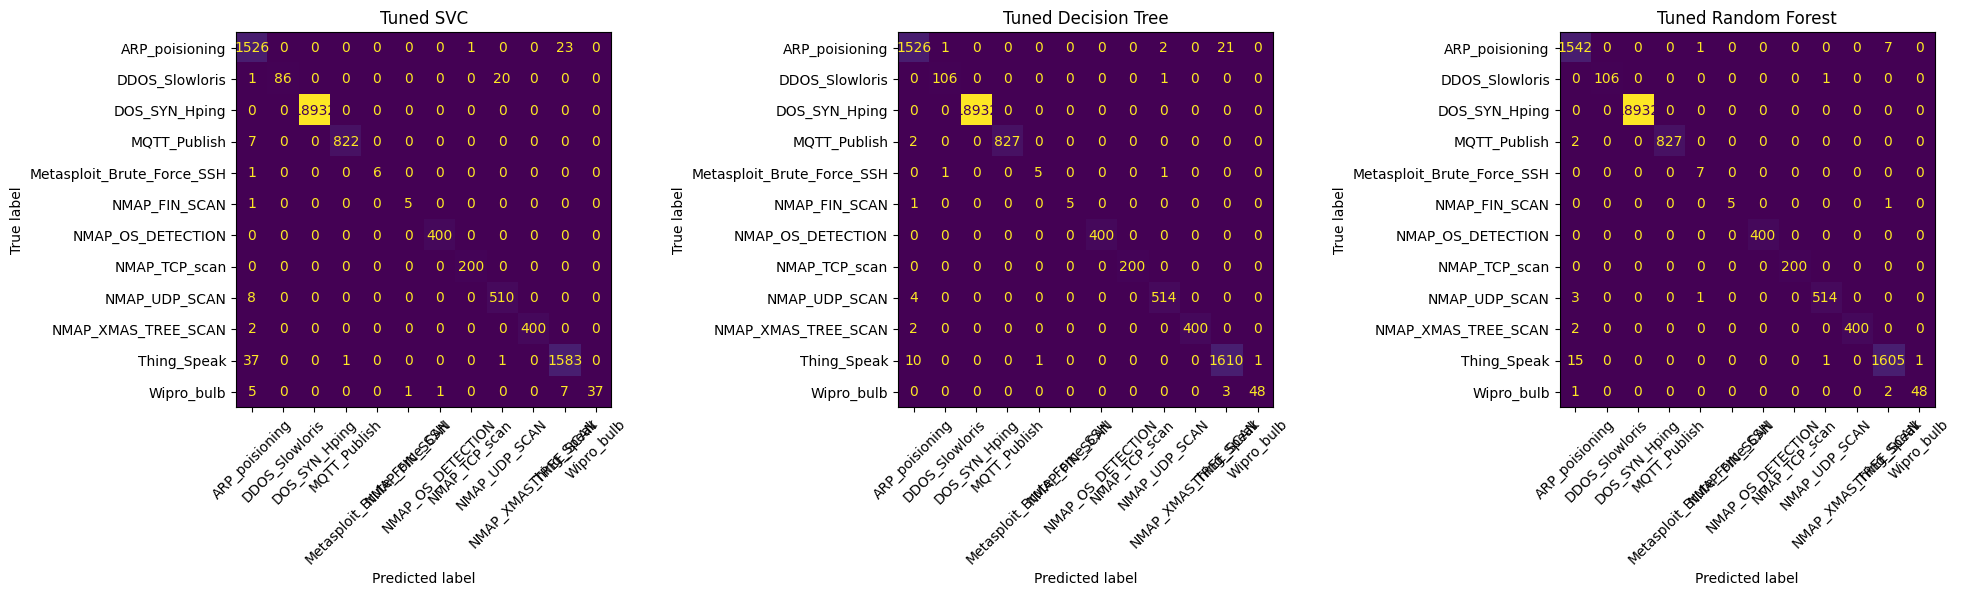

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_svc_tuned),
    display_labels=best_svc.classes_
).plot(ax=axes[0], xticks_rotation=45, colorbar=False)

axes[0].set_title("Tuned SVC")

ConfusionMatrixDisplay(
    confusion_matrix(y_test_tree, y_pred_dt_tuned),
    display_labels=best_dt.classes_
).plot(ax=axes[1], xticks_rotation=45, colorbar=False)

axes[1].set_title("Tuned Decision Tree")

ConfusionMatrixDisplay(
    confusion_matrix(y_test_tree, y_pred_rf_tuned),
    display_labels=best_rf.classes_
).plot(ax=axes[2], xticks_rotation=45, colorbar=False)

axes[2].set_title("Tuned Random Forest")

plt.tight_layout()
plt.show()

# Final Comparison Table

In [67]:
results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "SVC",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_svc_tuned),
        accuracy_score(y_test_tree, y_pred_dt_tuned),
        accuracy_score(y_test_tree, y_pred_rf_tuned)
    ],
    "Precision": [
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        precision_score(y_test, y_pred_svc_tuned, average="macro", zero_division=0),
        precision_score(y_test_tree, y_pred_dt_tuned, average="macro", zero_division=0),
        precision_score(y_test_tree, y_pred_rf_tuned, average="macro", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred_svc_tuned, average="macro", zero_division=0),
        recall_score(y_test_tree, y_pred_dt_tuned, average="macro", zero_division=0),
        recall_score(y_test_tree, y_pred_rf_tuned, average="macro", zero_division=0)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred_svc_tuned, average="macro", zero_division=0),
        f1_score(y_test_tree, y_pred_dt_tuned, average="macro", zero_division=0),
        f1_score(y_test_tree, y_pred_rf_tuned, average="macro", zero_division=0)
    ]
})

results

,Model,Accuracy,Precision,Recall,Macro F1
0,Naive Bayes,0.900260,0.639366,0.790712,0.583872
1,SVC,0.995249,0.977288,0.929276,0.950088
2,Decision Tree,0.997929,0.979975,0.953455,0.965666
3,Random Forest,0.998457,0.977717,0.977868,0.975967


# Comparison graph

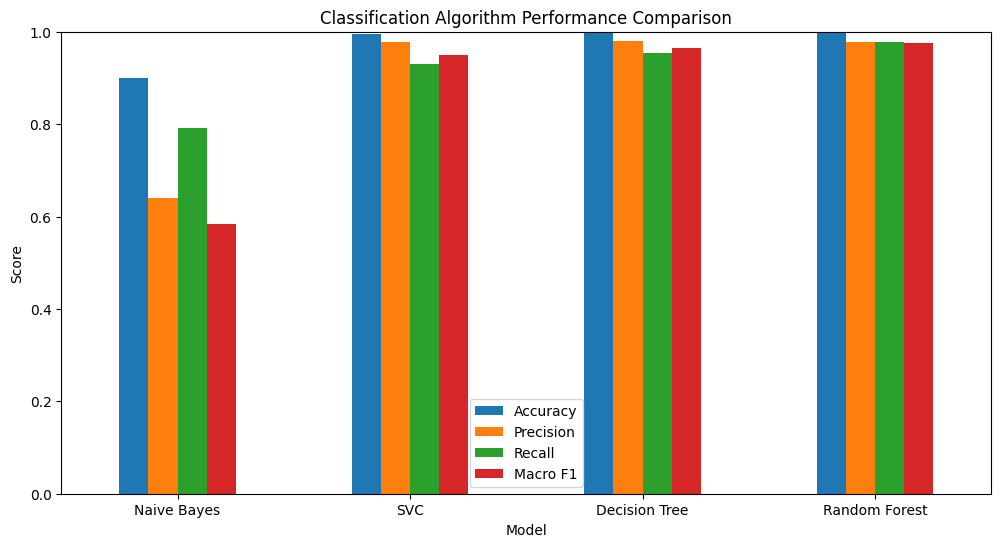

In [68]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Algorithm Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

##### computational time measurement

In [69]:
import time

start = time.time()
classifier.fit(X_train, y_train)
nb_train_time = time.time() - start

start = time.time()
y_pred_nb_time = classifier.predict(X_test)
nb_prediction_time = time.time() - start


start = time.time()
best_svc.fit(X_train, y_train)
svc_train_time = time.time() - start

start = time.time()
y_pred_svc_time = best_svc.predict(X_test)
svc_prediction_time = time.time() - start


start = time.time()
best_dt.fit(X_train_tree, y_train_tree)
dt_train_time = time.time() - start

start = time.time()
y_pred_dt_time = best_dt.predict(X_test_tree)
dt_prediction_time = time.time() - start


start = time.time()
best_rf.fit(X_train_tree, y_train_tree)
rf_train_time = time.time() - start

start = time.time()
y_pred_rf_time = best_rf.predict(X_test_tree)
rf_prediction_time = time.time() - start

In [70]:
time_results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "SVC",
        "Decision Tree",
        "Random Forest"
    ],
    "Training Time (seconds)": [
        nb_train_time,
        svc_train_time,
        dt_train_time,
        rf_train_time
    ],
    "Prediction Time (seconds)": [
        nb_prediction_time,
        svc_prediction_time,
        dt_prediction_time,
        rf_prediction_time
    ]
})

time_results

,Model,Training Time (seconds),Prediction Time (seconds)
0,Naive Bayes,0.577601,0.179546
1,SVC,20.420759,10.424610
2,Decision Tree,1.561309,0.010210
3,Random Forest,21.597522,0.496402


In [71]:
final_results = results.merge(
    time_results,
    on="Model"
)

final_results

,Model,Accuracy,Precision,Recall,Macro F1,Training Time (seconds),Prediction Time (seconds)
0,Naive Bayes,0.900260,0.639366,0.790712,0.583872,0.577601,0.179546
1,SVC,0.995249,0.977288,0.929276,0.950088,20.420759,10.424610
2,Decision Tree,0.997929,0.979975,0.953455,0.965666,1.561309,0.010210
3,Random Forest,0.998457,0.977717,0.977868,0.975967,21.597522,0.496402
